# Trabajo Práctico Especial: Análisis de Datos Inside Airbnb (Buenos Aires 2026)

## 1. Análisis Exploratorio Inicial de la Base

### 1.1. Origen, Alcance y Naturaleza de los Datos
* **Fuente de datos (Secundaria):** Los datos provienen de *Inside Airbnb*, un proyecto independiente que extrae información pública de la plataforma Airbnb mediante técnicas de *web scraping*. Al ser recolectados por terceros sin control directo sobre el proceso de muestreo original, constituyen una fuente secundaria que requiere un análisis de calidad.
* **Temporalidad y Alcance:** El dataset representa un corte transversal (*snapshot*) de la oferta de alquileres temporarios publicados en la Ciudad Autónoma de Buenos Aires (CABA) en 2026. 
* **Confiabilidad y Calidad de los Datos:** Al tratarse de una plataforma donde los anfitriones ingresan los datos de sus anuncios a mano, la base es altamente susceptible a errores humanos. 
### 1.2. Criterios de Exclusión y Reducción Dimensional 
El dataset original constaba de 90 columnas. Para focalizar el análisis exploratorio y evitar ruido estadístico, se descartaron 62 variables agrupadas bajo los siguientes criterios metodológicos:

* **Variables Totalmente Nulas:** Atributos con 0 valores no nulos en el corte temporal de CABA (ej. `host_response_rate`, `neighbourhood_group_cleansed`, `instant_bookable`, `host_acceptance_rate`).
* **Metadatos, URLs e Identificadores Internos:** Enlaces a perfiles/fotos, IDs de extracción y timestamps del *scraper* (ej. `listing_url`, `scrape_id`, `picture_url`, `last_scraped`). No aportan capacidad explicativa al modelo de negocio.
* **Redundancia y Alta Multicolinealidad:** 
  * Temporalidad: Se descartaron las variables expresadas en meses (ej. `hosts_time_as_host_months`) dado que se conservó su equivalente exacto en años.
  * Disponibilidad y Reseñas: Se eliminaron ventanas temporales cortas (`availability_30`, `number_of_reviews_l30d`) en favor de las variables anualizadas (`availability_365`, `number_of_reviews_ltm`).
  * Calificaciones: Se suprimieron las subcategorías de puntuación (limpieza, comunicación, ubicación) para evitar multicolinealidad, conservando únicamente el promedio general (`review_scores_rating`).
  * Inventario del anfitrión: Se eliminó el desglose específico (`_entire_homes`, `_private_rooms`), reteniendo solo el total (`calculated_host_listings_count`).
* **Texto Libre Inestructurado:** Descripciones narrativas o comerciales (`name`, `description`, `host_about`) que requerirían procesamiento de lenguaje natural (NLP).
* **Varianza Cercana a Cero / Constantes:** Variables como `has_availability` (casi 100% de la base comparte el mismo valor) o `license` (apenas 486 datos válidos sobre 29.685), las cuales no otorgan poder discriminatorio estadístico.

### 1.3. Descricion de las variables
* **`id`**: Identificador único de la publicación. int64 
* **`host_name`**: Nombre de pila del anfitrión.str
* **`hosts_time_as_user_years`**: Años de antigüedad en la plataforma como usuario. int64
* **`hosts_time_as_host_years`**: Años de experiencia operando como anfitrión. int64
* **`host_is_superhost`**: Etiqueta (verdadero/falso) que indica si el anfitrión tiene la medalla "Superhost". str
* **`neighbourhood_cleansed`**: Nombre del barrio oficial y validado estandarizadamente. str
* **`latitude`**: coordenada latitud. float64
* **`longitude`**: coordenada longitud. float64
* **`property_type`**: Tipo arquitectónico o específico de propiedad (ej. Cabaña, Loft, Departamento).  str
* **`accommodates`**: Capacidad máxima de huéspedes que pueden dormir en la propiedad. int64. Esta limitada a 16 por airbnb
* **`bathrooms`**: Cantidad numérica total de baños. float64
* **`bedrooms`**: Cantidad total de habitaciones.  float64
* **`amenities`**: Listado de todos los servicios y comodidades incluidos (Wifi, aire acondicionado, etc.). str
* **`price`**: Precio base diario del alquiler en formato texto (suele incluir símbolo de moneda). str
* **`minimum_nights`**: Cantidad mínima de noches exigida de forma general para poder reservar. float64
* **`maximum_nights`**: Cantidad máxima de noches permitida de forma general. Cuantitativa discreta. float64
* **`availability_365`**: Cantidad de días disponibles para reservar en los próximos 365 días. int64
* **`number_of_reviews_ltm`**: Cantidad de reseñas recibidas exclusivamente en los últimos 12 meses. int64
* **`estimated_occupancy_l365d`**: Cálculo estimado de la cantidad de días que la propiedad estuvo ocupada en el último año.int64
* **`estimated_revenue_l365d`**: Cálculo estimado de los ingresos económicos brutos generados en el último año. float64
* **`review_scores_rating`**: Puntaje promedio general del anuncio otorgado por los huéspedes. float64
* **`calculated_host_listings_count`**: Cantidad de anuncios totales del anfitrión limitados a esta misma ciudad/región. int64
* **`reviews_per_month`**: Frecuencia promedio mensual con la que la propiedad recibe reseñas. float64

### 1.4. Caracterización de los Atributos Seleccionados
Seleccionamos un subconjunto de 28 variables:

**A. Variables Cualitativas (Categóricas)**
* **Nominales:** `id` (estadísticamente nominal, opera como etiqueta), `host_name`, `neighbourhood_cleansed`, `property_type`, `amenities`.
* **Dicotómicas:** `host_is_superhost`.

**B. Variables Cuantitativas (Numéricas)**
* **Discretas:** `hosts_time_as_user_years`, `hosts_time_as_host_years`, `accommodates`, `bedrooms`, `minimum_nights`, `maximum_nights`, `availability_365`, `number_of_reviews_ltm`, `estimated_occupancy_l365d`, `calculated_host_listings_count`.
* **Continuas:** `latitude`,`longitude`,`bathrooms`, `price`, `estimated_revenue_l365d`, `review_scores_rating`, `reviews_per_month`.

In [34]:
import pandas as pd

ruta_archivo = "listings (1).csv.gz"

df_listings = pd.read_csv(ruta_archivo, compression='gzip', low_memory=False)
print(f"Dimensiones del dataset: {df_listings.shape}")
df_listings.info()

Dimensiones del dataset: (29685, 90)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  object 
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  object 
 4   source                                        29685 non-null  object 
 5   name                                          29685 non-null  object 
 6   description                                   28917 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29684 non-null  object 
 9   host_id                 

In [35]:
columnas_tpe = [
    'id', 'host_name', 'hosts_time_as_user_years', 'hosts_time_as_host_years', 
    'host_is_superhost', 'neighbourhood_cleansed','latitude', 'longitude', 
    'property_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 
    'price', 'minimum_nights', 'maximum_nights', 'availability_365', 
    'number_of_reviews_ltm', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 
    'review_scores_rating', 'calculated_host_listings_count', 'reviews_per_month'
]
df_copia = df_listings.copy()
df_copia = df_listings[columnas_tpe]
df_copia.describe()

,id,hosts_time_as_user_years,hosts_time_as_host_years,latitude,longitude,accommodates,bathrooms,bedrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews_ltm,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,calculated_host_listings_count,reviews_per_month
count,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,26244.000000,24500.000000,29682.000000,29682.000000,29685.000000,29685.000000,29685.000000,2.788800e+04,25957.000000,29685.000000,25957.000000
mean,9.329954e+17,7.506687,5.323362,-34.592114,-58.416274,2.941654,1.244494,1.354612,4.951722,563.329897,235.017147,12.602998,74.495873,9.570563e+06,4.780634,15.194240,1.481166
std,5.838355e+17,4.083517,4.046868,0.017920,0.030180,1.584278,0.703987,0.914463,18.114840,430.722323,116.160445,18.157164,82.642132,2.162264e+07,0.357190,32.782011,1.640487
min,1.150800e+04,0.000000,0.000000,-34.690056,-58.530890,1.000000,0.500000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000,1.000000,0.010000
25%,6.233293e+17,4.000000,2.000000,-34.603396,-58.435972,2.000000,1.000000,1.000000,1.000000,364.000000,148.000000,1.000000,6.000000,5.360180e+05,4.730000,1.000000,0.370000
50%,1.046350e+18,8.000000,4.000000,-34.591459,-58.418430,2.000000,1.000000,1.000000,2.000000,365.000000,264.000000,5.000000,42.000000,4.455030e+06,4.870000,3.000000,0.980000
75%,1.431417e+18,11.000000,8.000000,-34.581430,-58.390620,4.000000,1.000000,1.000000,3.000000,1125.000000,343.000000,18.000000,120.000000,1.316291e+07,4.980000,12.000000,2.050000
max,1.717830e+18,17.000000,15.000000,-34.534980,-58.355530,16.000000,22.000000,31.000000,730.000000,3659.000000,365.000000,581.000000,255.000000,1.285326e+09,5.000000,208.000000,41.660000


# 2. Limpieza y preparación de la base

**Objetivo de esta sección:** implementar las operaciones de limpieza necesarias sobre la base, detallando las acciones correctivas aplicadas y justificando cada una.

**Estructura del notebook**
1. Carga y copia de trabajo
2. Variables binarias del anfitrión (`t`/`f` → booleano)
3. Valores faltantes en la configuración física (`bathrooms`, `bedrooms`, `beds`)
4. Transformación de `amenities` (filtro por varianza + One-Hot Encoding)
5. Variable objetivo `price` (nulos y conversión a numérico)
6. Eliminación de filas con nulos en variables de estadía e ingresos
7. Tratamiento de outliers y de variables de reseñas *(pendiente de confirmar)*
8. Verificación final y resumen de las variables

## Resumen de la limpieza
| Problema | Variables | Acción |
|---|---|---|
| Texto `t`/`f` | `host_is_superhost` | Conversión a booleano |
| Nulos en estructura física | `bathrooms`, `bedrooms` | Imputación condicional en cascada (mediana por grupo) |
| Variable multivaluada | `amenities` | Filtro por varianza + One-Hot de 6 comodidades (`has_*`) |
| Nulos y formato en variable objetivo | `price` | *Listwise deletion* + conversión a `float` |
| Nulos marginales | `minimum_nights`, `maximum_nights`, `estimated_revenue_l365d` | Eliminación de filas |
| Valores extremos | `maximum_nights`, `number_of_reviews_ltm`, `calculated_host_listings_count` | Winsorización al percentil 99 *(a confirmar)* |
| Nulos por falta de historial | `review_scores_rating`, `reviews_per_month` | Imputación por mediana *(a confirmar)* |
| Sin problemas | `id`, `host_name`, `hosts_time_as_user_years`, `hosts_time_as_host_years`, `neighbourhood_cleansed`, `latitude`, `longitude`, `property_type`, `accommodates`, `availability_365`, `estimated_occupancy_l365d` | No se modificaron |

## 2.1. Carga y copia de trabajo
Trabajamos sobre una copia (`df_copia`) para conservar la base original intacta.

In [36]:
import numpy as np
df_copia.shape

(29685, 23)

## 2.2 Variables binarias del anfitrión
**Variables:** `host_is_superhost`

**Acción:** los valores originales eran texto (`'t'` / `'f'`). Se convirtieron a tipo booleano (`True` / `False`).

**Justificación:** son variables dicotómicas; el tipo booleano es más eficiente en memoria, evita errores de comparación entre strings y es el formato esperado por la mayoría de los métodos estadísticos y de modelado.

In [37]:
df_copia = df_copia.copy()
mapa_tf = {'t': True, 'f': False}

df_copia['host_is_superhost'] = df_copia['host_is_superhost'].map(mapa_tf)

df_copia['host_is_superhost'].value_counts()

host_is_superhost
False    17492
True     12193
Name: count, dtype: int64

## 2.3. Valores faltantes en la configuración física
**Variables:** `bathrooms`, `bedrooms`

### 2.3.1. Diagnóstico y mecanismo de pérdida
Se detectaron aproximadamente 3.000 nulos en `bathrooms`. Se descartó que los datos falten de forma completamente aleatoria (MCAR): se asume un mecanismo ***Missing At Random* (MAR)**, ya que la cantidad de baños esperada está directamente relacionada con la capacidad máxima de la propiedad (`accommodates`).

### 2.3.2. Decisión metodológica
* Se descartó **eliminar filas** para no perder ~10% de la muestra.
* Se descartó la **imputación global** (media/mediana de toda la columna), porque introduce valores constantes que atenúan artificialmente la variabilidad y las correlaciones.
* Se aplicó una **imputación condicional**: los nulos se reemplazan por la mediana del subgrupo de propiedades con igual capacidad. Así se rescatan los registros minimizando el impacto sobre la varianza y preservando la forma de la distribución.

### 2.3.3. Imputación condicinal
El orden refleja la dependencia real de un alojamiento y evita violar dependencias lógicas:
1. **Atributo raíz:** `accommodates` (capacidad máxima) es la variable independiente principal.
2. **Espacios:** `bathrooms` y `bedrooms` se imputan con la mediana por `accommodates`.


In [38]:
df_copia = df_copia.copy()
df_copia['bathrooms'] = df_copia['bathrooms'].fillna(
    df_copia.groupby('accommodates')['bathrooms'].transform('median'))
df_copia['bedrooms'] = df_copia['bedrooms'].fillna(
    df_copia.groupby('accommodates')['bedrooms'].transform('median'))

df_copia[['bathrooms', 'bedrooms']].isnull().sum()

bathrooms    0
bedrooms     0
dtype: int64

## 2.4. Transformación de `amenities`
**Variables generadas:** `has_refrigerator`, `has_bed_linens`, `has_elevator`, `has_parking`, `has_balcony_patio`, `has_pool`  
**Variable eliminada:** `amenities` (texto multivaluado original)

### 2.4.1. Enfoque descartado
Seleccionar las 5 comodidades más frecuentes por conteo absoluto presentaba dos problemas:
1. **Redundancia y multicolinealidad:** `Dishes and silverware`, `Cooking basics` o `Refrigerator` están casi directamente asociados a `Kitchen`, duplicando información.
2. **Bajo valor de negocio:** atributos triviales de alta frecuencia (`Hangers`, `Hot water`) no explican la variación de tarifas ni de demanda.

### 2.4.2. Exploración de frecuencias
Se limpió el formato de la lista (corchetes, comillas) y se midió el porcentaje de propiedades que posee cada comodidad agrupada mediante expresiones regulares.

In [39]:
# Frecuencia absoluta de cada comodidad individual
amenities_limpios = (df_copia['amenities']
                     .str.replace(r'\[|\]|"|\'', '', regex=True)
                     .str.split(r',\s*'))
conteo_amenities = amenities_limpios.explode().value_counts()
print("--- Top 15 amenities más frecuentes ---")
print(conteo_amenities.head(15))

--- Top 15 amenities más frecuentes ---
amenities
Kitchen                  27510
Wifi                     26707
Hot water                24117
Dishes and silverware    22694
Cooking basics           22002
Hangers                  21650
Bed linens               21637
Air conditioning         19969
Hair dryer               19805
Refrigerator             19448
Microwave                18608
TV                       18516
Bidet                    18301
Essentials               18170
Elevator                 17830
Name: count, dtype: int64


In [40]:
# Porcentaje de presencia por macro-categoría (regex)
patrones_amenities = {
    'Wifi / Internet': 'Wifi|Internet',
    'Kitchen (Cocina)': 'Kitchen',
    'TV (Cualquier tipo)': 'TV',
    'Air conditioning (AC)': 'Air conditioning|AC',
    'Hot water': 'Hot water',
    'Bed linens': 'Bed linens',
    'Refrigerator': 'Refrigerator',
    'Pool (Pileta)': 'Pool',
    'Parking (Estacionamiento)': 'Parking',
    'Gym (Gimnasio)': 'Gym',
    'Elevator (Ascensor)': 'Elevator',
    'Balcony / Patio': 'Balcony|Patio|Terrace|Backyard'
}

resultados = {nombre: df_copia['amenities'].str.contains(patron, case=False, na=False, regex=True).mean() * 100
              for nombre, patron in patrones_amenities.items()}

df_porcentajes = (pd.DataFrame(list(resultados.items()), columns=['Amenity_Agrupado', 'Porcentaje (%)'])
                  .sort_values(by='Porcentaje (%)', ascending=False)
                  .reset_index(drop=True))
display(df_porcentajes.round(2))

,Amenity_Agrupado,Porcentaje (%)
0,Wifi / Internet,99.14
1,Air conditioning (AC),97.47
2,Kitchen (Cocina),94.52
3,TV (Cualquier tipo),92.22
4,Hot water,82.68
5,Refrigerator,73.68
6,Bed linens,72.89
7,Elevator (Ascensor),60.06
8,Parking (Estacionamiento),55.94
9,Balcony / Patio,51.80


### 2.4.3. Filtro por varianza y One-Hot Encoding
Para no generar un dataset excesivamente esparso, no se codificaron todas las categorías: se aplicó un **filtro por varianza**.

* **Descartadas (varianza cercana a cero):** `Wifi` (>99%), `Air conditioning` (>97%), `Kitchen` (>94%) y `TV` (>92%). Al estar presentes en casi toda la oferta se comportan como constantes: su entropía es mínima y no aportan información para diferenciar propiedades ni justificar precios.
* **Conservadas:** `Refrigerator`, `Bed linens`, `Elevator`, `Parking`, `Balcony/Patio` y `Pool`, cuya presencia es intermedia. En ese rango la varianza y la entropía son altas, lo que da poder discriminatorio para segmentar el mercado.
* **Transformación:** las 6 comodidades se convirtieron en **variables dicotómicas (1/0)** mediante regex y se eliminó la columna original.

In [41]:
df_copia = df_copia.copy()
amenities_seleccionados = {
    'has_refrigerator': 'Refrigerator',
    'has_bed_linens': 'Bed linens',
    'has_elevator': 'Elevator',
    'has_parking': 'Parking',
    'has_balcony_patio': 'Balcony|Patio|Terrace|Backyard',
    'has_pool': 'Pool'
}

for col_name, pattern in amenities_seleccionados.items():
    df_copia[col_name] = (df_copia['amenities']
                          .str.contains(pattern, case=False, na=False, regex=True)
                          .astype(int))

# Se elimina la columna de texto original
df_copia = df_copia.drop(columns=['amenities'])
df_copia.describe()

,id,hosts_time_as_user_years,hosts_time_as_host_years,latitude,longitude,accommodates,bathrooms,bedrooms,minimum_nights,maximum_nights,...,estimated_revenue_l365d,review_scores_rating,calculated_host_listings_count,reviews_per_month,has_refrigerator,has_bed_linens,has_elevator,has_parking,has_balcony_patio,has_pool
count,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29682.000000,29682.000000,...,2.788800e+04,25957.000000,29685.000000,25957.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000
mean,9.329954e+17,7.506687,5.323362,-34.592114,-58.416274,2.941654,1.224583,1.295520,4.951722,563.329897,...,9.570563e+06,4.780634,15.194240,1.481166,0.736837,0.728887,0.600640,0.559407,0.518039,0.269261
std,5.838355e+17,4.083517,4.046868,0.017920,0.030180,1.584278,0.672056,0.844914,18.114840,430.722323,...,2.162264e+07,0.357190,32.782011,1.640487,0.440358,0.444542,0.489775,0.496467,0.499683,0.443583
min,1.150800e+04,0.000000,0.000000,-34.690056,-58.530890,1.000000,0.500000,0.000000,1.000000,1.000000,...,0.000000e+00,1.000000,1.000000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.233293e+17,4.000000,2.000000,-34.603396,-58.435972,2.000000,1.000000,1.000000,1.000000,364.000000,...,5.360180e+05,4.730000,1.000000,0.370000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.046350e+18,8.000000,4.000000,-34.591459,-58.418430,2.000000,1.000000,1.000000,2.000000,365.000000,...,4.455030e+06,4.870000,3.000000,0.980000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
75%,1.431417e+18,11.000000,8.000000,-34.581430,-58.390620,4.000000,1.000000,1.000000,3.000000,1125.000000,...,1.316291e+07,4.980000,12.000000,2.050000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.717830e+18,17.000000,15.000000,-34.534980,-58.355530,16.000000,22.000000,31.000000,730.000000,3659.000000,...,1.285326e+09,5.000000,208.000000,41.660000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 2.5. Variable objetivo `price`
### 2.5.1. Nulos
Se detectaron **1.792 nulos**. Al ser la variable objetivo del análisis de mercado, se descartó cualquier técnica de imputación (mediana, regresión, KNN) para no introducir sesgos artificiales en su distribución. Se **eliminaron las filas** afectadas: se asume una pérdida de información menor a cambio de preservar la autenticidad de la métrica financiera.

### 2.5.2. Conversión a numérico
El precio estaba almacenado como texto con símbolo `$` y separador de miles. Se eliminaron esos caracteres con regex y se convirtió a `float`, necesario para cualquier operación aritmética o estadística.

### 2.5.3 Eliminación de filas con nulos en estadía e ingresos
**Variables:** `minimum_nights`, `maximum_nights`, `estimated_revenue_l365d`

**Acción:** se eliminaron las filas con nulos en estas variables.

**Justificación:** la cantidad de nulos es baja y se trata de variables sin una variable auxiliar confiable para imputar. En `estimated_revenue_l365d`, además, el valor deriva de `price` y de la ocupación estimada, por lo que imputarlo generaría datos artificiales sobre una métrica financiera.

In [42]:
df_copia = df_copia.dropna(subset=['price'])
print("Nulos restantes en 'price':", df_copia['price'].isnull().sum())

df_copia['price'] = df_copia['price'].str.replace(r'[\$,]', '', regex=True).astype(float)
df_copia['price'].describe()

df_copia = df_copia.dropna(subset=['minimum_nights', 'maximum_nights'])
df_copia = df_copia.dropna(subset=['estimated_revenue_l365d'])
df_copia.shape

Nulos restantes en 'price': 0


(27885, 28)

### 2.6. Tratamiento de Outliers y Variables de Reseñas

#### 2.6.1. Eliminación de valores extremos
**Variables:** `maximum_nights`, `number_of_reviews_ltm`, `calculated_host_listings_count`
Se detectaron valores atípicos que distorsionan severamente el análisis visual y las medidas de tendencia central (ej. alojamientos con configuraciones irreales de más de 3 años de estadía máxima, o mega-agencias con cientos de propiedades). Tras verificar mediante cuantificación que los registros ubicados por encima del percentil 99 representan menos del 1% de los datos para cada variable, se procedió a **eliminar estas filas**. Esta decisión purifica la distribución para el análisis exploratorio sin comprometer la representatividad estadística de la muestra general.

#### 2.6.2. Preservación de nulos estructurales en reseñas
**Variables:** `review_scores_rating`, `reviews_per_month`
Estas variables presentan nulos que responden a una ausencia lógica de datos (propiedades nuevas o sin reservas consolidadas). Se decidió **no aplicar ninguna técnica de imputación** para mantener la fidelidad de la métrica. Alterar estos nulos inyectaría calificaciones artificiales a propiedades no probadas por el mercado, sesgando el análisis de reputación.

#### 2.6.3. Conservación de Outliers Naturales
No se aplicó recorte sobre variables financieras o estructurales fundamentales como `price` o `minimum_nights`. Los valores atípicos en estas métricas representan nichos legítimos del mercado real (propiedades de ultra lujo o alquileres de formato mensual). Su eliminación constituiría una manipulación de la muestra que ocultaría la amplitud real del mercado inmobiliario porteño; por lo tanto, se conservaron intactos en el dataset, aplicando recortes de percentiles exclusivamente para la renderización de las visualizaciones gráficas.

In [43]:
cols_outliers = ['maximum_nights', 'number_of_reviews_ltm', 'calculated_host_listings_count']

print("--- Recuento de valores extremos (> Percentil 99) ---")
for col in cols_outliers:
    umbral_99 = df_copia[col].quantile(0.99)
    cantidad_outliers = (df_copia[col] > umbral_99).sum()
    porcentaje = (cantidad_outliers / len(df_copia)) * 100
    print(f"{col}: {cantidad_outliers} registros ({porcentaje:.2f}%) por encima del valor {umbral_99:.2f}")

--- Recuento de valores extremos (> Percentil 99) ---
maximum_nights: 12 registros (0.04%) por encima del valor 1125.00
number_of_reviews_ltm: 273 registros (0.98%) por encima del valor 80.00
calculated_host_listings_count: 208 registros (0.75%) por encima del valor 186.00


In [44]:
cols_outliers = ['maximum_nights', 'number_of_reviews_ltm', 'calculated_host_listings_count']

print(f"Total de filas antes del recorte: {len(df_copia)}")

# Aplicamos un filtrado iterativo conservando solo los valores <= al percentil 99
for col in cols_outliers:
    umbral_99 = df_copia[col].quantile(0.99)
    df_copia = df_copia[df_copia[col] <= umbral_99]

print(f"Total de filas después del recorte: {len(df_copia)}")

Total de filas antes del recorte: 27885
Total de filas después del recorte: 27392


### 3. Distribución de Variables: Comportamiento y Asimetrías

Los histogramas muestran distribuciones muy alejadas de la normal. Predominan las colas largas a la derecha, los valores “redondos” por defecto de la plataforma y los picos en valores extremos. Varias variables están graficadas con zoom por percentil (p95, p98 o p99), por lo que las colas reales son más largas que lo visible.

#### 3.1. Variables con Fuerte Asimetría Positiva (Sesgo a la Derecha)
* **Precio e ingresos (`price`, `estimated_revenue_l365d`):** `price` tiene la moda en torno a los $80.000-$100.000 y una cola larga hacia propiedades premium (el gráfico se corta en p95, con valores de hasta $300.000). `estimated_revenue_l365d` está inflada en cero (más de 8.000 anuncios sin ingresos estimados) y decae lentamente hasta ~$30 millones anuales.
* **Capacidad (`accommodates`, `bedrooms`, `bathrooms`):** La oferta es mayormente de departamentos chicos. `accommodates` tiene la moda en 2 personas, con un segundo escalón en 4. `bedrooms` y `bathrooms` se concentran en 1, con caídas fuertes en 2, 3 y 4 o más.
* **Anfitrión y reglas (`calculated_host_listings_count`, `minimum_nights`):** Domina el anfitrión de 1 propiedad (~10.000 casos), seguido por el de 2. La cola, de hasta ~70 propiedades, corresponde a agencias e inversores. `minimum_nights` se concentra en 1 a 3 noches, con picos aislados en valores redondos (7, 15, 30), típicos del alquiler temporario y mensual.
* **Antigüedad como anfitrión (`hosts_time_as_host_years`):** Moda en 2-3 años, con muchos anfitriones nuevos (~0 años) y una cola hasta 15 años. Hay un pico secundario cerca de los 7 años.
* **Actividad (`number_of_reviews_ltm`, `reviews_per_month`):** Cerca de 10.000 anuncios no recibieron reseñas en el último año (nuevos, inactivos o poco demandados). El resto decae rápido, y casi todos están por debajo de 3 reseñas por mes.
* **Ocupación (`estimated_occupancy_l365d`):** Hay una gran masa en 0-10 días (~7.700 anuncios) y un decaimiento progresivo. Como esta variable es una estimación y no un dato observado, el pico en ~255 días no es un comportamiento real. Es consistente con el tope del 70% de ocupación (0,7 × 365 ≈ 255) que Inside Airbnb aplica en su modelo.

#### 3.2. Variables con Asimetría Negativa (Sesgo a la Izquierda)
* **Reputación (`review_scores_rating`):** Casi toda la masa está entre 4,5 y 5, con la moda en 5.
* **Disponibilidad (`availability_365`):** A diferencia de una bimodal clásica, el pico dominante está en 365 días (~5.400 anuncios siempre abiertos). El resto es irregular, con pequeños picos intermedios y muy poco en torno a 0. 

#### 3.3. Distribuciones Polarizadas o Multimodales
* **Estadía máxima (`maximum_nights`):** Concentrada en tres valores: 365 y 1125 (este último parece ser el valor por defecto de la plataforma) y, en menor medida, valores bajos (~30) y 730. Por eso tiene poca información real y se parece más a una variable categórica.
* **Antigüedad como usuario (`hosts_time_as_user_years`):** Es irregular y multimodal (picos cerca de 3 y 10 años), sin sesgo marcado. Probablemente refleja distintas “olas” de incorporación de anfitriones a la plataforma.

#### 3.4. Distribuciones Geográficas (Pseudo-Normales)
* **Latitud (`latitude`):** Es casi normal y se centra cerca de -34,60, con un pequeño hombro hacia el norte (zona Belgrano/Núñez).
* **Longitud (`longitude`):** Es asimétrica a la izquierda y bimodal: un pico cerca de -58,43 (corredor Palermo/Villa Crespo) y otro cerca de -58,37 (zona Centro/Puerto Madero/San Telmo). La cola izquierda corresponde a barrios más periféricos hacia el oeste.

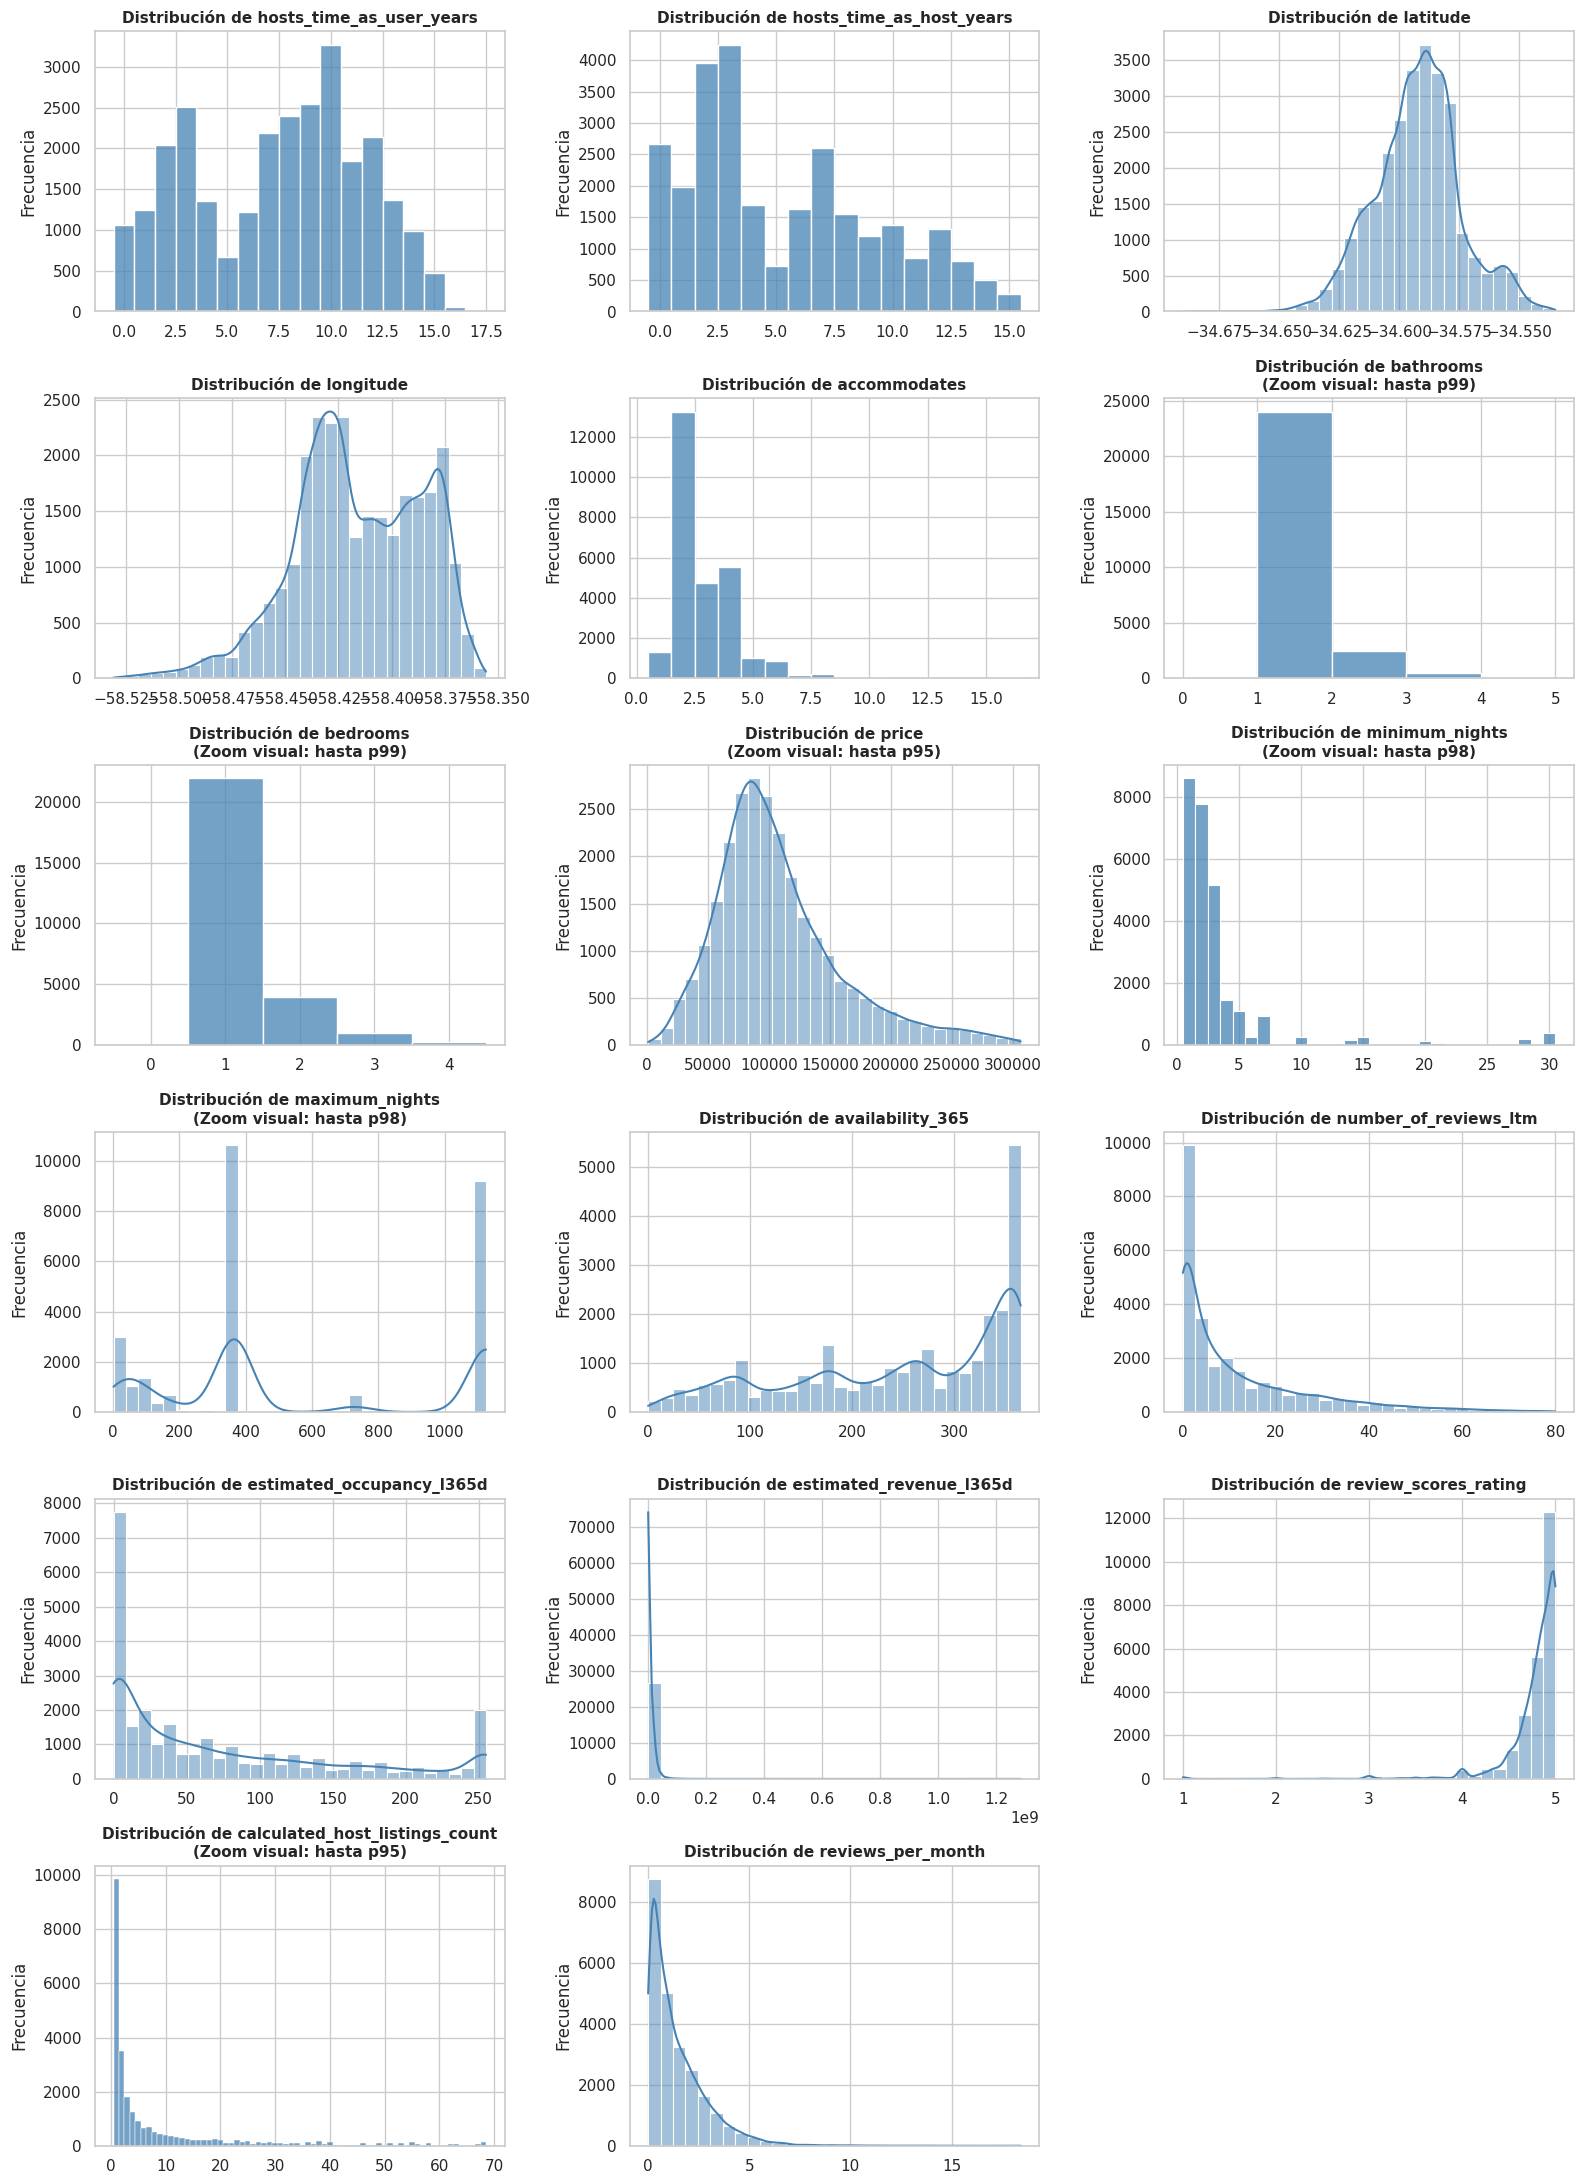

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

variables_numericas = [
    'hosts_time_as_user_years', 'hosts_time_as_host_years', 'latitude', 'longitude', 
    'accommodates', 'bathrooms', 'bedrooms', 'price', 'minimum_nights', 
    'maximum_nights', 'availability_365', 'number_of_reviews_ltm', 
    'estimated_occupancy_l365d', 'estimated_revenue_l365d', 
    'review_scores_rating', 'calculated_host_listings_count', 'reviews_per_month'
]

variables_discretas = [
    'hosts_time_as_user_years', 'hosts_time_as_host_years', 'accommodates', 
    'bathrooms', 'bedrooms', 'minimum_nights', 'calculated_host_listings_count'
]

variables_con_zoom = {
    'price': 0.95,
    'minimum_nights': 0.98,
    'maximum_nights': 0.98,
    'bathrooms': 0.99,
    'bedrooms': 0.99,
    'calculated_host_listings_count': 0.95
}

# Creamos una serie local para el precio (si es texto) sin modificar df_copia
if df_copia['price'].dtype == 'object':
    s_price = df_copia['price'].replace(r'[\$,]', '', regex=True).astype(float)
else:
    s_price = df_copia['price']

fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(16, 22))
axes = axes.flatten()
sns.set_theme(style="whitegrid")

for i, col in enumerate(variables_numericas):
    if col in df_copia.columns:
        # Usamos la serie local s_price si la columna es 'price', evitando mutar df_copia
        if col == 'price':
            datos = s_price.dropna()
        else:
            datos = df_copia[col].dropna()
            
        titulo = f'Distribución de {col}'
        
        # Aplicamos el zoom visual (solo afecta al gráfico, no al DataFrame)
        if col in variables_con_zoom:
            percentil = variables_con_zoom[col]
            datos = datos[datos <= datos.quantile(percentil)]
            titulo += f'\n(Zoom visual: hasta p{int(percentil*100)})'
            
        # Lógica de graficado: Discreta vs Continua
        if col in variables_discretas:
            sns.histplot(datos, discrete=True, kde=False, ax=axes[i], color='steelblue')
        else:
            sns.histplot(datos, bins=30, kde=True, ax=axes[i], color='steelblue')
        
        axes[i].set_title(titulo, fontweight='bold', fontsize=11)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Frecuencia')

# Eliminamos los ejes sobrantes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# 4. Hipostisis Validacion
### Hipótesis 1 (univariada): Baja ocupación media anual

#### Planteo

**Enunciado.** La ocupación anual estimada de los alojamientos de Airbnb en CABA (`estimated_occupancy_l365d`) tiene una media inferior al 45 % del año, es decir, a 164,25 días ocupados de 365.

**Variable.** `estimated_occupancy_l365d`, cuantitativa discreta (días ocupados en los últimos 365).

**Justificación y valor generado.** En el alquiler temporario el ingreso depende de la tarifa y de las noches efectivamente ocupadas, por lo que la ocupación es el principal indicador de rentabilidad. Se toma el 45 % como umbral de referencia. Si la media resultara significativamente menor, el mercado estaría en general subutilizado y un inversor no debería proyectar ocupaciones altas, sino trabajar con escenarios conservadores.

#### Planteo del contraste

* **Hipótesis** (unilateral a izquierda, porque se afirma que la media es *inferior* al umbral):
  * $H_0: \mu \geq 164{,}25$ días ($\geq 45\,\%$ del año).
  * $H_1: \mu < 164{,}25$ días ($< 45\,\%$ del año).
  * donde $\mu$ es la media poblacional de días de ocupación anual estimada.
* **Nivel de significancia:** $\alpha = 0{,}05$.

count    27392.00
mean        74.94
std         81.50
min          0.00
25%          6.00
50%         42.00
75%        120.00
max        255.00
Name: estimated_occupancy_l365d, dtype: float64


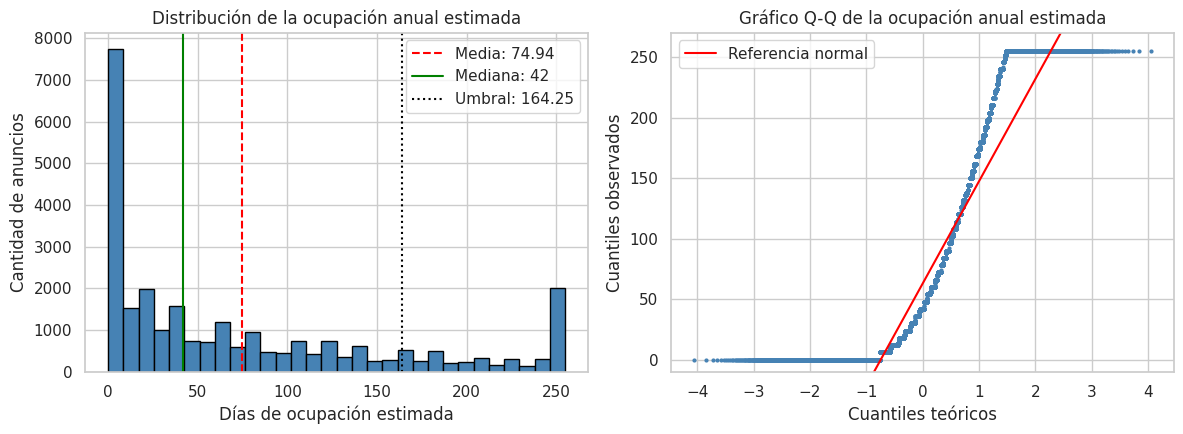

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

col = "estimated_occupancy_l365d"
umbral = 0.45 * 365          # 164,25 días
x = df_copia[col].dropna()

print(x.describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Histograma
ax[0].hist(x, bins=30, edgecolor="black", color="steelblue")
ax[0].axvline(x.mean(), color="red", linestyle="--", label=f"Media: {x.mean():.2f}")
ax[0].axvline(x.median(), color="green", label=f"Mediana: {x.median():.0f}")
ax[0].axvline(umbral, color="black", linestyle=":", label=f"Umbral: {umbral:.2f}")
ax[0].set_xlabel("Días de ocupación estimada")
ax[0].set_ylabel("Cantidad de anuncios")
ax[0].set_title("Distribución de la ocupación anual estimada")
ax[0].legend()

# QQ plot con recta de referencia por los cuartiles
(teoricos, ordenados), _ = stats.probplot(x, dist="norm")
z1, z3 = stats.norm.ppf([0.25, 0.75])
q1, q3 = np.percentile(x, [25, 75])
pend = (q3 - q1) / (z3 - z1)
orig = q1 - pend * z1
ax[1].scatter(teoricos, ordenados, s=4, color="steelblue")
ax[1].plot(teoricos, orig + pend * teoricos, color="red", label="Referencia normal")
ax[1].set_ylim(-10, 270)
ax[1].set_xlabel("Cuantiles teóricos")
ax[1].set_ylabel("Cuantiles observados")
ax[1].set_title("Gráfico Q-Q de la ocupación anual estimada")
ax[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

#### Análisis gráfico

**Histograma.** La distribución es asimétrica a la derecha y presenta dos acumulaciones: una en 0 días (de los anuncios, que no tienen reseñas en el último año) y otra en ~255 días, el tope del modelo de estimación de Inside Airbnb. Entre ambas la frecuencia decrece de forma progresiva. La media (74,9 días) supera a la mediana (42 días) por efecto de la cola derecha. El umbral de 164,25 días queda lejos de ambas.

**Gráfico Q-Q.** Los puntos forman una S y se apartan de la recta de referencia, con dos tramos horizontales: uno en 0 días (cola inferior, ≈ 23 % de los datos) y otro en 255 días (cola superior, ≈ 7 %). Es el patrón de una variable inflada en cero y truncada en el extremo superior, que no sigue una distribución normal.

En conjunto, la forma de la distribución no es normal, pero tanto la media como la mediana quedan muy por debajo del umbral, por lo que el gráfico anticipa el resultado del contraste.

In [53]:
# Submuestra de 5000: con n > 5000 el p-valor de Shapiro no es exacto
W, p = stats.shapiro(x.sample(5000, random_state=42))
print(f"Shapiro-Wilk (n = 5000): W = {W:.3f}, p = {p:.3g}")

Shapiro-Wilk (n = 5000): W = 0.833, p = 3.4e-58


Para evaluar el supuesto de normalidad, se aplicó la prueba de Shapiro-Wilk sobre una muestra aleatoria de 5.000 observaciones. Dado que el p-valor es inferior al nivel de significación establecido (α = 0,05), se rechaza la hipótesis nula de normalidad.


In [54]:
# Test t para una media, unilateral a izquierda (H1: mu < umbral)
t, p = stats.ttest_1samp(x, popmean=umbral, alternative="less")
ic = stats.t.interval(0.95, df=len(x) - 1, loc=x.mean(), scale=stats.sem(x))
print(f"n = {len(x)} | media = {x.mean():.2f} ({x.mean()/365:.1%} del año) | t = {t:.2f} | p = {'< 0.001' if p < 0.001 else round(p, 4)}")
print(f"IC 95% de la media: ({ic[0]:.2f}, {ic[1]:.2f})")
print("Decisión:", "se rechaza H0" if p < 0.05 else "no se rechaza H0")

# Sensibilidad 1: solo anuncios activos (sin los ceros)
act = df_copia.loc[df_copia["number_of_reviews_ltm"] > 0, col]
t_a, p_a = stats.ttest_1samp(act, popmean=umbral, alternative="less")
print(f"Solo activos: n = {len(act)} | media = {act.mean():.2f} | t = {t_a:.1f} | p = {'< 0.001' if p_a < 0.001 else round(p_a, 4)}")

# Sensibilidad 2: dependencia por anfitrión (df_listings tiene host_id)
por_host = df_listings.groupby("host_id").size()
multi = por_host[por_host > 1]
print(f"Anfitriones: {len(por_host)} | con más de un anuncio: {len(multi)} ({len(multi)/len(por_host):.1%}) "
      f"| anuncios de esos anfitriones: {multi.sum()/por_host.sum():.1%}")

un_por_host = df_listings.sample(frac=1, random_state=42).drop_duplicates("host_id")
x_h = un_por_host[col].dropna()
t_h, p_h = stats.ttest_1samp(x_h, popmean=umbral, alternative="less")
print(f"Un anuncio por anfitrión: n = {len(x_h)} | media = {x_h.mean():.2f} | t = {t_h:.1f} | p = {'< 0.001' if p_h < 0.001 else round(p_h, 4)}")

n = 27392 | media = 74.94 (20.5% del año) | t = -181.36 | p = < 0.001
IC 95% de la media: (73.98, 75.91)
Decisión: se rechaza H0
Solo activos: n = 21195 | media = 96.86 | t = -122.1 | p = < 0.001
Anfitriones: 14556 | con más de un anuncio: 3748 (25.7%) | anuncios de esos anfitriones: 63.6%
Un anuncio por anfitrión: n = 14556 | media = 71.50 | t = -137.3 | p = < 0.001


#### Conclusión

**Decisión.** Con $\alpha = 0{,}05$ se rechaza $H_0$ ($t = -181{,}36 < -1{,}645$; $p < 0{,}001$). **Se confirma la hipótesis:** la ocupación anual media estimada de los anuncios de Airbnb en CABA es inferior al 45 % del año.

**Cómo leer el resultado**

* **La media es muy baja.** Es de 74,9 días, el 20,5 % del año, menos de la mitad del umbral (164,25 días).
* **El resultado es estable.** El intervalo de confianza del 95 % de la media es (74,0 ; 75,9) días. Todo el intervalo queda muy por debajo de 164,25, así que la conclusión no depende de la muestra y no se explica por azar. De hecho, $H_0$ se rechazaría con cualquier umbral mayor a ~76 días (≈ 21 % del año), por lo que la conclusión no depende de haber elegido el 45 %.
* **El anuncio típico rinde aún menos que el promedio.** La mediana (42 días) es menor que la media, porque unos pocos anuncios con ocupación muy alta la elevan.

**Por qué el test t es válido aunque la variable no sea normal.** La hipótesis es sobre una media y la muestra es grande (n = 27.392). En ese caso la media muestral se distribuye aproximadamente normal aunque los datos no lo sean (teorema central del límite), por lo que el test t sigue siendo confiable.

**Verificaciones de robustez.** Se repitió el contraste para comprobar que el resultado no dependa de decisiones del análisis:

| Versión | Por qué se hizo | n | Media (días) | $t$ | Resultado |
|---|---|---|---|---|---|
| Todos los anuncios | Análisis principal | 27.392 | 74,9 | −181,4 | Se rechaza $H_0$ |
| Solo anuncios activos (con reseñas en el último año) | ≈ 23 % de los anuncios tiene ocupación 0 y podría estar bajando el promedio | 21.195 | 96,9 | −122,1 | Se rechaza $H_0$ |
| Un anuncio por anfitrión | Los anuncios de un mismo anfitrión no son independientes | 14.556 | 71,5 | −137,3 | Se rechaza $H_0$ |

La conclusión es la misma en las tres versiones. Incluso sin los anuncios inactivos, la media (96,9 días, 26,5 % del año) queda muy por debajo del 45 %.

**Implicancia para el inversor.** No conviene proyectar ocupaciones cercanas al 45 % del año. Un escenario conservador puede basarse en la mediana (42 días) y uno optimista en la media de los anuncios activos (~97 días).

**Limitaciones**

* **La ocupación es una estimación.** Se calcula a partir de las reseñas con el modelo de Inside Airbnb y tiene un tope de ~255 días (70 % del año), por lo que la conclusión se refiere a la ocupación *estimada*, no a la observada.
* **Dependencia entre anuncios.** En la base completa (29.685 anuncios) hay 14.556 anfitriones, y el 25,7 % de ellos (3.748) tiene más de un anuncio. Esos anfitriones concentran el 63,6 % de los anuncios, de modo que las observaciones no son plenamente independientes y el p-valor tiende a ser más optimista de lo real. Por eso se hizo la verificación con un anuncio por anfitrión, que arroja el mismo resultado.

### Hipótesis 2 (bivariada): Confianza del Superhost

#### Planteo

**Enunciado.** La insignia de "Superhost" (`host_is_superhost`) genera una ventaja competitiva medible en el mercado, traduciéndose en una mediana de ocupación anual (`estimated_occupancy_l365d`) significativamente superior a la de los anfitriones estándar. La validación algorítmica de Airbnb actúa como un sello de confianza que decanta en mayor conversión de reservas. El contraste evalúa la parte medible de la afirmación: la diferencia de medianas de ocupación entre ambos grupos.

**Variables.**
* **Independiente (agrupación):** `host_is_superhost`, cualitativa nominal dicotómica.
* **Dependiente (respuesta):** `estimated_occupancy_l365d`, cuantitativa discreta (días ocupados en los últimos 365).

**Justificación y valor generado.** Para obtener la insignia, el anfitrión debe sostener métricas exigentes (por ejemplo, cancelaciones menores al 1 %, respuestas rápidas, calificación superior a 4,8 y un mínimo de estadías). Validar esta hipótesis permite cuantificar si ese esfuerzo operativo se traduce en mayor ocupación. Si los Superhosts ocupan significativamente más, la recomendación para un inversor sería destinar presupuesto a mejorar la atención al cliente para conseguir la insignia, entendiéndolo como una inversión en marketing y no como un gasto.

#### Planteo del contraste

* **Hipótesis** (unilateral, porque se afirma que los Superhosts tienen *más* ocupación):
  * $H_0: \theta_{Superhost} = \theta_{Estándar}$ (misma mediana de ocupación anual).
  * $H_1: \theta_{Superhost} > \theta_{Estándar}$.
* **Nivel de significancia:** $\alpha = 0{,}05$.

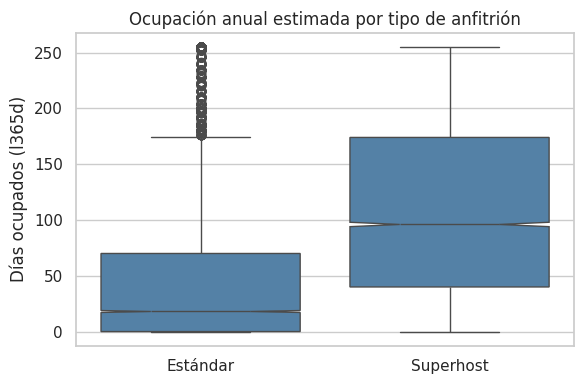

           count  median        mean
grupo                               
Estándar   15927    18.0   49.393922
Superhost  11465    96.0  110.437244
Spearman = 0.418, p-valor = 0


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

col = "estimated_occupancy_l365d"

d = df_copia[["host_is_superhost", col]].dropna().copy()
d["super_bin"] = d["host_is_superhost"].astype(int)   # True -> 1, False -> 0
d["grupo"] = d["super_bin"].map({1: "Superhost", 0: "Estándar"})

# Boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(data=d, x="grupo", y=col, notch=True, order=["Estándar", "Superhost"], color="steelblue")
plt.title("Ocupación anual estimada por tipo de anfitrión")
plt.xlabel("")
plt.ylabel("Días ocupados (l365d)")
plt.tight_layout()
plt.show()

# Medianas por grupo
print(d.groupby("grupo")[col].agg(["count", "median", "mean"]))

# Spearman
rho, p = stats.spearmanr(d["super_bin"], d[col])
print(f"Spearman = {rho:.3f}, p-valor = {p:.4g}")

#### Análisis descriptivo y gráfico

| Grupo | n | Mediana | Media | Q1 | Q3 |
|---|---|---|---|---|---|
| Estándar | 15.927 | 18 | 49,4 | ≈ 0 | ≈ 70 |
| Superhost | 11.465 | 96 | 110,4 | ≈ 40 | ≈ 175 |

El gráfico de cajas (con *notches*) muestra una diferencia marcada entre ambos grupos:

* **Estándar:** distribución comprimida hacia valores bajos. El 75 % de los anuncios no supera los ~70 días ocupados.
* **Superhost:** caja más alta (mayor dispersión) y desplazada hacia arriba, con el 50 % central entre ~40 y ~175 días.
* **Muescas:** no se superponen, lo que sugiere que las medianas poblacionales difieren. La del grupo Estándar es más angosta por su mayor tamaño muestral y su menor rango intercuartílico. 
* **Valores atípicos:** el grupo Estándar tiene una cola densa de atípicos hasta ~255 días, es decir, una ocupación alta es atípica *dentro de ese grupo*. En los Superhosts el bigote llega a ese mismo valor sin marcar atípicos. Ese tope no es un comportamiento real: coincide con el límite del modelo de Inside Airbnb (70 % × 365 ≈ 255 días), por lo que la variable, al ser una estimación, no llega al año completo.
* **Asociación:** Spearman $\rho = 0{,}418$ ($p < 0{,}001$), asociación positiva moderada.

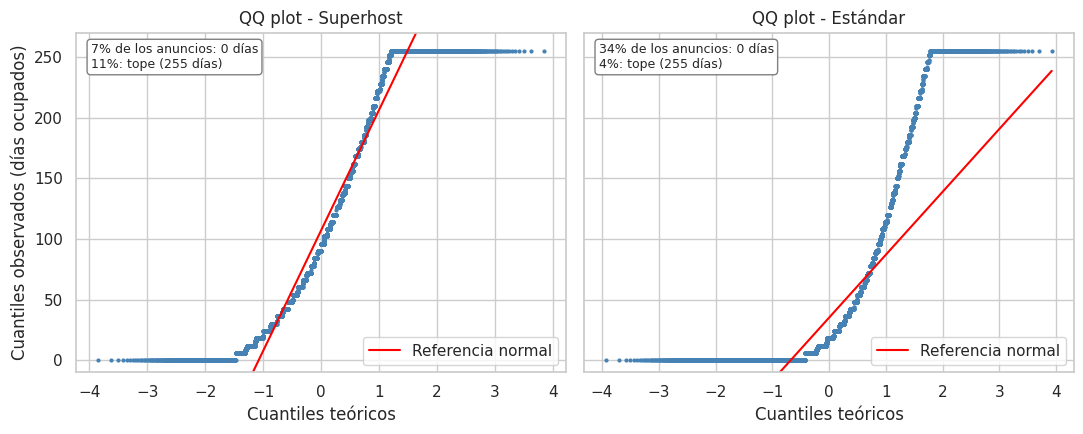

Shapiro Superhost: ShapiroResult(statistic=np.float64(0.9118951588734336), pvalue=np.float64(4.201004603693161e-47))
Shapiro Estándar:  ShapiroResult(statistic=np.float64(0.7268815265695505), pvalue=np.float64(1.2793815614389338e-67))
Levene: LeveneResult(statistic=np.float64(1299.6168348902154), pvalue=np.float64(4.3372898785928207e-278))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

col = "estimated_occupancy_l365d"
sup = df_copia.loc[df_copia["host_is_superhost"] == True, col].dropna()
est = df_copia.loc[df_copia["host_is_superhost"] == False, col].dropna()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, (nombre, x) in zip(ax, [("Superhost", sup), ("Estándar", est)]):
    (teoricos, ordenados), _ = stats.probplot(x, dist="norm")

    # Recta de referencia por los cuartiles
    z1, z3 = stats.norm.ppf([0.25, 0.75])
    q1, q3 = np.percentile(x, [25, 75])
    pend = (q3 - q1) / (z3 - z1)
    orig = q1 - pend * z1

    a.scatter(teoricos, ordenados, s=4, color="steelblue")
    a.plot(teoricos, orig + pend * teoricos, color="red", lw=1.5, label="Referencia normal")
    a.set_ylim(-10, 270)
    a.set_title(f"QQ plot - {nombre}")
    a.set_xlabel("Cuantiles teóricos")
    a.legend(loc="lower right")

    # Peso de las dos pilas
    pct_cero = (x == 0).mean()
    pct_tope = (x == x.max()).mean()
    a.text(0.03, 0.97,
           f"{pct_cero:.0%} de los anuncios: 0 días\n{pct_tope:.0%}: tope ({x.max():.0f} días)",
           transform=a.transAxes, va="top", fontsize=9,
           bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray"))

ax[0].set_ylabel("Cuantiles observados (días ocupados)")
plt.tight_layout()
plt.show()

# Shapiro-Wilk (submuestra de 5000: con n > 5000 el p-valor no es exacto)
print("Shapiro Superhost:", stats.shapiro(sup.sample(5000, random_state=42)))
print("Shapiro Estándar: ", stats.shapiro(est.sample(5000, random_state=42)))

# Homocedasticidad
print("Levene:", stats.levene(sup, est, center="median"))

#### Verificación de supuestos

* **Normalidad (Shapiro-Wilk sobre una submuestra aleatoria de 5.000 anuncios por grupo, y QQ plot):** Superhost $W = 0{,}912$ y Estándar $W = 0{,}727$, ambos con $p < 0{,}001$. Se rechaza la normalidad en los dos grupos. Los QQ plots lo confirman: los puntos se apartan de la recta de referencia y forman dos tramos horizontales, uno en 0 días (7 % de los Superhosts y 34 % de los Estándar) y otro en el tope de ~255 días del modelo de estimación (11 % y 4 %, respectivamente). La variable está inflada en cero y truncada en el extremo superior.
* **Homocedasticidad (Levene, centrado en la mediana):** estadístico $= 1299{,}6$, $p < 0{,}001$. Se rechaza la igualdad de varianzas.

**Elección del test:** el test t es robusto a cierta asimetría con muestras grandes, pero aquí la distribución está inflada en cero y truncada, y además la hipótesis se formuló sobre medianas y no sobre medias, por lo que se descarta. Mann-Whitney se plantea bajo homogeneidad de varianzas, que tampoco se cumple. Se opta por la **prueba de la mediana**, que no supone normalidad ni varianzas iguales y contrasta directamente lo que afirma la hipótesis: las medianas.

In [ ]:
chi2, p_bil, med_global, tabla = stats.median_test(sup, est)

prop_sup = tabla[0, 0] / len(sup)   # % de Superhosts sobre la mediana global
prop_est = tabla[0, 1] / len(est)   # % de Estándar sobre la mediana global

# Unilateral (H1: Superhost > Estándar): solo vale si la diferencia va en el sentido de H1
p_uni = p_bil / 2 if prop_sup > prop_est else 1 - p_bil / 2

print(f"Medianas: Superhost {sup.median():.0f} | Estándar {est.median():.0f}")
print(f"Sobre la mediana global ({med_global:.0f}): Superhost {prop_sup:.1%} vs Estándar {prop_est:.1%}")
print(f"chi2 = {chi2:.1f} | z = {chi2**0.5:.1f} | p unilateral = {'< 0.001' if p_uni < 0.001 else round(p_uni, 4)}")
print("Decisión:", "se rechaza H0" if p_uni < 0.05 else "no se rechaza H0")

Medianas: Superhost 96 | Estándar 18
Sobre la mediana global (42): Superhost 71.7% vs Estándar 33.3%
chi2 = 3929.4 | z = 62.7 | p unilateral = < 0.001
Decisión: se rechaza H0


#### Conclusión

Con $\alpha = 0{,}05$ **se rechaza $H_0$** ($\chi^2 = 3929{,}4$; $z \approx 62{,}7 > 1{,}645$; $p < 0{,}001$). La mediana de ocupación anual estimada de los Superhosts (96 días) supera en 78 días a la de los anfitriones estándar (18 días), y el 71,7 % de los Superhosts queda por encima de la mediana global (42 días) contra el 33,3 % de los Estándar. 

**Se confirma la hipótesis en su parte medible:** el status de Superhost se asocia con una mediana de ocupación significativamente superior.

No puede afirmarse que la insignia *genere* esa ventaja ni que se traduzca en mayor conversión de reservas, por las siguientes limitaciones:

* La ocupación se estima a partir de las reseñas, por lo que incluso entre anuncios activos la diferencia puede reflejar mayor volumen de reseñas y no necesariamente más reservas.
* Para obtener la insignia se exige un mínimo de estadías, de modo que los anuncios sin actividad casi nunca la tienen.
* `host_is_superhost` es un atributo a nivel anfitrión. Al existir dueños con múltiples anuncios (calculated_host_listings_count), las observaciones no son estrictamente independientes, lo que vuelve al p-valor más optimista de lo real. Sin embargo, la robustez de la evidencia absorbe este sesgo: el estadístico observado ($\chi^2 = 3929{,}4$) supera por un factor de 1.450 al valor crítico unilateral ($\approx 2{,}71$). Para que el test dejara de ser significativo, la muestra efectiva debería reducirse a unas inverosímiles ~19 observaciones. Sumado a esto, la enorme brecha en las estadísticas descriptivas (96 vs. 18 días) no depende de este supuesto distribucional
* Es una asociación y no causalidad: los Superhosts pueden diferir también en antigüedad, ubicación o precio.

**Implicancia para el inversor:** alcanzar la insignia mediante una mejor atención al cliente es una estrategia promisoria, pero no un retorno garantizado. La hipótesis multivariada permite controlar por estos factores.